# 00.03 — Return + γ + Bellman

<div><span style="display:inline-block;background:#54A24B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REWARD</span><span style="display:inline-block;background:#00A6A6;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">GAMMA</span><span style="display:inline-block;background:#ECA82C;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">Q</span><span style="display:inline-block;background:#22A06B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TARGET</span></div>

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo=Path.cwd()
if repo.name=="notebooks": repo=repo.parent
sys.path.insert(0,str(repo))
from lineworld import LineWorld
from visuals import *
legend()

<div style="border-left:10px solid #00A6A6;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#00A6A6">GAMMA</div><div style="font-size:21px;font-weight:800;margin-top:4px">γ = discount factor</div><div style="font-size:15px;line-height:1.55;margin-top:8px">How much a reward/value one step further in the future counts. γ=.95 retains 95% per extra step.</div></div>

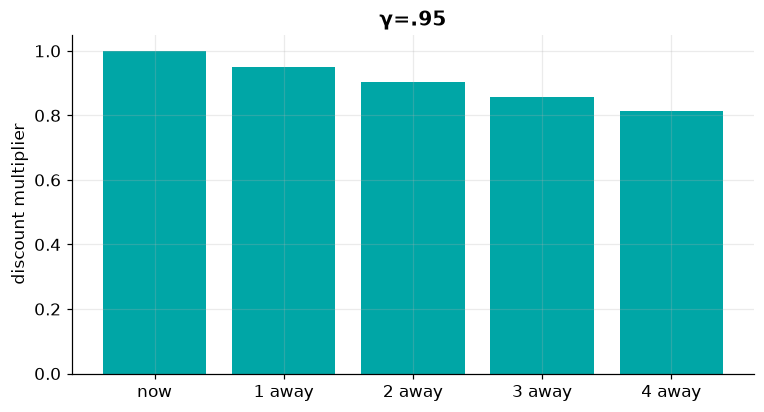

[1.0, 0.95, 0.9025, 0.8573749999999999, 0.8145062499999999]


In [2]:
gamma=.95
vals=[gamma**i for i in range(5)]
plt.figure(figsize=(8,4)); plt.bar(["now","1 away","2 away","3 away","4 away"],vals,color=COLORS["GAMMA"]); plt.ylabel("discount multiplier"); plt.title("γ=.95"); plt.show()
print(vals)

**Q\*(s,a)** is the expected discounted cumulative reward from taking action a in state s and then behaving optimally afterward. That is an action-value, not a probability.

<div style="border-left:10px solid #22A06B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#22A06B">TARGET</div><div style="font-size:21px;font-weight:800;margin-top:4px">Bellman one-step look-ahead</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Value now = reward now + discounted value of the best continuation. This is the backup/tree intuition from David Silver.</div></div>

Q*(state 0, RIGHT) = 0.740309
Q*(state 1, RIGHT) = 0.800325
Q*(state 2, RIGHT) = 0.863500
Q*(state 3, RIGHT) = 0.930000
Q*(state 4, RIGHT) = 1.000000


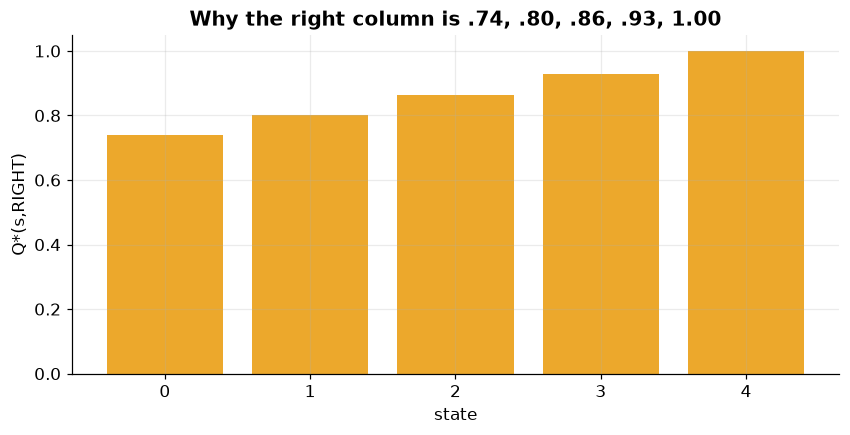

In [3]:
gamma=.95; cost=-.02
q4=1.0; q3=cost+gamma*q4; q2=cost+gamma*q3; q1=cost+gamma*q2; q0=cost+gamma*q1
vals=[q0,q1,q2,q3,q4]
for s,v in enumerate(vals): print(f"Q*(state {s}, RIGHT) = {v:.6f}")
plt.figure(figsize=(9,4)); plt.bar(range(5),vals,color=COLORS["Q"]); plt.xticks(range(5)); plt.xlabel("state"); plt.ylabel("Q*(s,RIGHT)"); plt.title("Why the right column is .74, .80, .86, .93, 1.00"); plt.show()

### State 3 RIGHT = 0.93 exactly

`-0.02 + 0.95 × 1.00 = 0.93`.

So **0.93 is not caused by exploration randomness**. It comes from immediate step cost + discounted best future action-value.

Q[next_obs] = Q[4] = [0.8635 1.    ]
np.max(Q[next_obs]) = 1.0


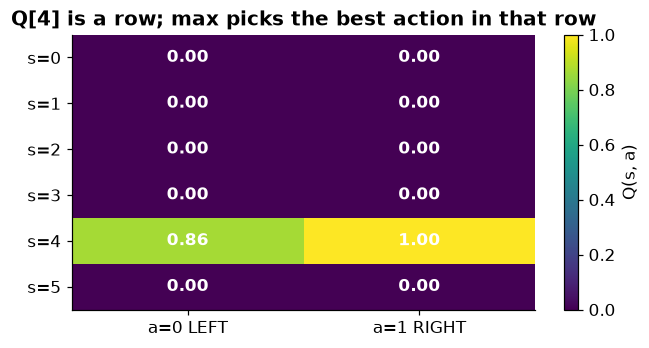

In [4]:
Q=np.zeros((6,2)); Q[4]=[.8635,1.0]; next_obs=4
print("Q[next_obs] = Q[4] =",Q[next_obs])
print("np.max(Q[next_obs]) =",np.max(Q[next_obs]))
fig=q_heatmap(Q,"Q[4] is a row; max picks the best action in that row")
plt.show()

`future = np.max(Q[next_obs])` does **not** mean max of a set of next observations. If `next_obs=4`, Python reads row `Q[4]`, e.g. `[0.86,1.00]`, then max chooses `1.00`.

### Is this backpropagation?

No. It is a **Bellman / temporal-difference backup**: learned value is bootstrapped backward through transitions. Backprop is gradient calculus through a neural network. DQN uses both, but tabular Q-learning here does not.